# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:
1. train_from_iterator отримує окремі вірші, тож BPE рахує частоти пар символів усередині кожного вірша окремо. Якби ми передали один суцільний рядок, тренер працював би з одним величезним блоком тексту, а це зайве навантаження на пам'ять, яке на великому корпусі може закінчитися OOM. Крім того, на стиках віршів з'явилися б штучні пари (останній символ одного твору й перший символ наступного), які враховувалися б у статистиці злиттів, хоча між цими творами немає жодного зв'язку. Словник від цього не зламався б, але став би трохи гіршим, а природна межа «документ» зникла б.
2. Токенізація складається з чотирьох етапів. Нормалізація очищає й уніфікує текст (регістр, зайві пробіли, Unicode-нормалізація). Пре-токенізація ділить текст на великі шматки, наприклад слова, і задає межі, за які токени не виходять; у демо ByteLevel працює на рівні байтів. Модель токенізації (BPE, WordPiece або Unigram) розбиває кожен шматок на підслова зі словника. Постобробка додає спеціальні токени на кшталт `<eos>` і формує службові поля, як-от attention_mask. Зворотну операцію виконує декодер. Я спирався на загальні знання, тому звір цей опис зі сторінкою 6.8 курсу HF.
3. `<unk>` (unknown) замінює фрагмент, якого немає у словнику. У ByteLevel BPE він майже не трапляється, бо будь-який текст розкладається на байти з базового алфавіту. `<eos>` (end of sequence) позначає кінець документа; ми вставляємо його між віршами, щоб модель бачила, де закінчується один твір і починається інший.


In [2]:
#task 4
from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

poems_dataset = load_dataset("RudyiVT/ukrainian-poems", split="train")
poems_df = poems_dataset.to_pandas()
poems = poems_df["context_poem"].dropna().tolist()
print("Усього віршів:", len(poems))

SPECIAL_TOKENS = ["<unk>", "<eos>"]

def tok_stats(vocab_size):
    tk = Tokenizer(models.BPE(unk_token="<unk>"))
    tk.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tk.decoder = decoders.ByteLevel()
    tr = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS)
    tk.train_from_iterator(poems, trainer=tr)

    unk_id = tk.get_vocab()["<unk>"]
    total_tokens, unk_count = 0, 0
    for start in range(0, len(poems), 1000):
        for enc in tk.encode_batch(poems[start:start + 1000]):
            total_tokens += len(enc.ids)
            unk_count += sum(1 for i in enc.ids if i == unk_id)
    return total_tokens / len(poems), unk_count / total_tokens, total_tokens

results = {}
for vs in (16000, 5000):
    avg, unk, total = tok_stats(vs)
    results[vs] = (avg, unk, total)
    print(f"VOCAB_SIZE={vs}: токенів/вірш={avg:.1f}, "
          f"усього токенів={total:,}, частка <unk>={unk:.4%}")

ratio = results[5000][0] / results[16000][0]
print(f"\nЗі словником 5000 послідовності довші в {ratio:.2f} раза")

Усього віршів: 17918
VOCAB_SIZE=16000: токенів/вірш=1027.1, усього токенів=18,404,050, частка <unk>=0.0000%
VOCAB_SIZE=5000: токенів/вірш=1205.4, усього токенів=21,598,411, частка <unk>=0.0000%

Зі словником 5000 послідовності довші в 1.17 раза


4. Після зменшення словника з 16000 до 5000 середня кількість токенів на вірш зросла з 1027,1 до 1205,4, тобто послідовності стали довшими в 1,17 раза (корпус виріс з 18,4 до 21,6 млн токенів). Частка <unk> в обох випадках дорівнює нулю. Менший словник не підвищує <unk>, бо токенізатор працює на рівні байтів: базовий алфавіт містить усі 256 байтів, тож будь-який текст можна закодувати, і в найгіршому разі слово розкладається на окремі байти, а не на невідомий токен. Менший словник означає менше виконаних злиттів, тому слова й морфеми розпадаються на дрібніші шматки, і той самий текст займає більше токенів.

  Це впливає на те, скільки тексту модель бачить за один раз. CONTEXT_LEN задано в токенах (64), тож зі словником 5000 у вікно потрапляє приблизно в 1,17 раза менше реального тексту (менше слів), і модель має коротший контекст у термінах слів. Водночас той самий корпус дає більше токенів, тобто більше позицій для передбачення, але кожна з них несе менше інформації. Крім того, ширші розбиття збільшують навантаження на модель: їй треба «збирати» слова з дрібніших фрагментів.

  Збільшення на 17 %, а не в рази, пояснюється тим, що навіть при 5000 найчастіші слова й закінчення української мови все ще мають власні токени, а втрата стискання стосується переважно рідкісних слів.

5. Без `<eos>` кінець одного вірша безпосередньо переходить у початок наступного, і модель бачить безперервний потік. Вона вчиться передбачати перший рядок нового вірша як продовження попереднього, тобто вивчає залежності, яких насправді немає. Крім того, вона ніколи не бачить сигналу завершення, тому під час генерації не вміє «вирішити», що текст закінчився.

6. Це одновимірні тензори типу int64 форми (N,). Кожен елемент є id токена зі словника BPE, тобто числом від 0 до VOCAB_SIZE-1, включно з id токена <eos>. Усі вірші склеєні в одну послідовність: train_data містить перші 90 % за порядком, val_data останні 10 %.

In [3]:
# Підготовка середовища та питання 7
import gc
import numpy as np
import torch
from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CONTEXT_LEN = 64
BATCH_SIZE = 64
VOCAB_SIZE = 16000
SPECIAL_TOKENS = ["<unk>", "<eos>"]

poems_df = load_dataset("RudyiVT/ukrainian-poems", split="train").to_pandas()
poems_list = poems_df["context_poem"].dropna().tolist()

bpe_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe_tokenizer.decoder = decoders.ByteLevel()
bpe_trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS)
bpe_tokenizer.train_from_iterator(poems_list, trainer=bpe_trainer)
EOS_ID = bpe_tokenizer.get_vocab()["<eos>"]

chunks = []
for start in range(0, len(poems_list), 1000):
    for enc in bpe_tokenizer.encode_batch(poems_list[start:start + 1000]):
        chunks.append(np.array(enc.ids + [EOS_ID], dtype=np.int32))
data = torch.from_numpy(np.concatenate(chunks).astype(np.int64))
del chunks
gc.collect()

split_idx = int(len(data) * 0.9)
train_data, val_data = data[:split_idx], data[split_idx:]

def get_batch(split: str):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - CONTEXT_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LEN] for i in ix])
    y = torch.stack([source[i + 1:i + CONTEXT_LEN + 1] for i in ix])
    return x.to(device), y.to(device)

#task 7
xb, yb = get_batch("train")
print("Форма батчу x:", xb.shape, " y:", yb.shape)

assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN)
assert torch.equal(xb[:, 1:], yb[:, :-1]), "y має бути x, зсунутим на один токен"
print("assert пройдено")

Форма батчу x: torch.Size([64, 64])  y: torch.Size([64, 64])
assert пройдено


8. У матриці scores рядок i відповідає запиту позиції i, а стовпець j ключу позиції j. Нижньотрикутна маска залишає лише пари j ≤ i, тобто кожен токен бачить себе й попередні, але не наступні. Верхньотрикутна дозволила б дивитися в майбутнє. Заборонені позиції заповнюються -inf, тому після softmax їхня вага дорівнює нулю. Без маски модель під час тренування просто підглядала б правильну відповідь і швидко досягла б майже нульового loss, нічого не вивчивши. Під час генерації майбутніх токенів ще немає, тож поведінка розійшлася б із тренуванням, а текст вийшов би безглуздим.

9. Найкращий і останній чекпоінти збігаються, якщо val_loss спадає або тримається на плато до кінця тренування, тобто перенавчання не настало. Вони різняться, якщо після певного мінімуму val_loss починає рости, а train_loss продовжує падати: тоді найкращим є чекпоінт із мінімумом, а не останній. У моєму прогоні найкращий чекпоінт припав на iter 7999 із val_loss = 5,657, тобто він збігається з останнім. Обидві криві плавно спадають до кінця, val_loss жодного разу не пішов угору, а розрив між train (5,580) і val (5,657) малий. Це випадок збігу чекпоінтів: модель за 8000 ітерацій ще недонавчена, і loss міг би падати далі.

10. Було змінено лише одне значення в 3.1: EVAL_INTERVAL = 50. Крива навчання отримала 161 точку замість 33 і стала детальнішою, особливо на початку: видно, що loss різко падає з ~9,8 до ~7,5 уже за перші 100 ітерацій, чого з кроком 250 не побачити. На пізніх етапах (після ~4000 ітерацій) додаткові точки дають переважно шум: val_loss подекуди підскакує на кілька сотих (наприклад, близько ітерацій 4300-4400), хоча загальний тренд спадний. Тож крива стала інформативнішою на початку, але не обов'язково гладшою на плато, бо гладкість обмежена шумом оцінки по 50 батчах. Тренування зайняло 10,9 хв проти 7,0 хв, тобто на 3,9 хв (близько 56 %) довше: замість 33 оцінок виконується 161, і кожна становить 2 × EVAL_ITERS = 100 прямих проходів без градієнтів. Робити інтервал ще меншим немає сенсу, бо оцінка стає дорожчою за саме тренування, а різниця між сусідніми точками вже зараз менша за шум вимірювання. Різниця фінального val_loss (5,657 проти 5,637) теж у межах шуму, а не наслідок зміни інтервалу.

11. Температура ділить логіти на T перед softmax: p_i = exp(z_i / T) / Σ_j exp(z_j / T). За T < 1 різниці між логітами зростають, розподіл стає гострішим, і майже вся ймовірність дістається найімовірнішому токену, тому текст при temperature=0.2 передбачуваний і повторюваний (при T → 0 це жадібне декодування). За T = 1 розподіл лишається таким, яким його видала модель. За T > 1 значення z_i / T стискаються до нуля, розподіл вирівнюється, і при temperature=1.4 менш імовірні токени отримують помітну вагу. Якщо T дуже велика, розподіл наближається до рівномірного: будь-який токен зі словника стає майже однаково ймовірним, а тому текст виглядає випадковим.

12. Параметр top_p задає nucleus sampling. Токени сортуються за спаданням ймовірності, і залишається найменша множина, сума ймовірностей якої не менша за p. Решта відкидається, ймовірності перенормовуються, і наступний токен вибирається вже з цього «ядра». На відміну від top_k, де кількість кандидатів фіксована, розмір ядра адаптивний: коли модель упевнена, у ньому один-два токени, а коли ні, то багато. Малий top_p (наприклад, 0,1) дає майже детермінований вибір, а великий (0,9 і вище) зберігає різноманітність.

13. З enable_thinking=False модель одразу видає продовження речення українською, без жодних службових блоків, і довжина відповіді вкладається в ліміт 300 токенів. Якість залежить від температури: при temperature=0.2 і 0.8 текст зв'язний і граматично правильний, а при temperature=1.4 з'являються спотворені слова і менш логічні звороти, що узгоджується з теорією про вирівнювання розподілу при високій температурі.
З enable_thinking=True результат зовсім інший. Кожна відповідь починається з блоку `<think>`, у якому модель англійською міркує про завдання: уточнює, що треба продовжити речення українською, обмірковує сюжет і навіть плутається у фактах (називає Житомирську політехніку то харківською, то хмельницькою). Міркування з'їло весь бюджет max_new_tokens=300, тому у всіх трьох випадках генерація обірвалася посеред речення, а самого продовження історії ми так і не побачили. Тобто для практичного результату відповідь стала гіршою: вона довша, повільніша й не містить того, що просили. Температура вплинула на міркування слабко: початок блоку `<think>` майже однаковий для 0.2, 0.8 і 1.4, а різниця проявилася лише в деталях формулювань. Щоб побачити фінальну відповідь, потрібно значно збільшити max_new_tokens (наприклад, до 1000 і більше), а за нього доведеться платити часом генерації. Режим із міркуванням доречний для складних задач (математика, логіка, код), а для простого творчого продовження речення достатньо enable_thinking=False.

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

In [4]:
import gc
import random
import pandas as pd
from datasets import load_dataset

N_DOCS = 15000

streamed_ds = load_dataset("overthelex/ukrainian-court-decisions", "default",
                           split="train", streaming=True).take(N_DOCS)
rows = list(streamed_ds)
df = pd.DataFrame(rows)

TEXT_COL = "text"
assert TEXT_COL in df.columns, f"Немає колонки {TEXT_COL}"

docs = df[TEXT_COL].dropna().astype(str).tolist()
random.seed(42)
random.shuffle(docs)
corpus_text = "\n\n".join(docs)

del df, rows
gc.collect()

print("Документів:", len(docs))
print("Розмір корпусу:", len(corpus_text), "символів")
print("Слів:", len(corpus_text.split()), " унікальних:", len(set(w.lower() for w in corpus_text.split())))
print("Приклад:\n", docs[0][:500])

README.md:   0%|          | 0.00/9.37k [00:00<?, ?B/s]

Документів: 15000
Розмір корпусу: 90293092 символів
Слів: 12498095  унікальних: 293888
Приклад:
 Позивач звернувся до суду з позовом до відповідачки про стягнення з неї заборгованості за Кредитним договором в сумі 21600 гривень. В позовній заяві позивач вказав, що 24.11.2011 року між ПАТ комерційний банк «ПриватБанк» та ОСОБА_1 був укладений Кредитний договір № б/н, відповідно до якого остання отримала у строковий кредит грошові кошти в сумі 15000 гривень у вигляді встановленого кредитного ліміту на платіжну картку. Згідно до умов цього Договору, відповідачка зобов'язалася погашати кредит щ


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [5]:
# --- 6.2: розминка, train_new_from_iterator на основі Qwen ---
from transformers import AutoTokenizer
import pandas as pd
from tokenizers import Tokenizer, models, trainers, pre_tokenizers

def batch_iterator(batch_size=1000):
    subset = docs[:5000]
    for i in range(0, len(subset), batch_size):
        yield subset[i:i + batch_size]

old_tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
new_tok = old_tok.train_new_from_iterator(batch_iterator(), vocab_size=5000)

sample = docs[0][:300]
print("Старий Qwen:", len(old_tok.tokenize(sample)), "токенів")
print("Новий (5000):", len(new_tok.tokenize(sample)), "токенів")
print(new_tok.tokenize("заборгованість відшкодування"))

# --- 6.5-6.7: BPE, WordPiece, Unigram + порівняння (1.1) ---
VOCAB = 500
SPECIAL = ["[UNK]"]
train_docs = docs[:2000]
test_text = " ".join(docs[2000:2100])

def make(kind):
    if kind == "BPE":
        tk = Tokenizer(models.BPE(unk_token="[UNK]"))
        tr = trainers.BpeTrainer(vocab_size=VOCAB, special_tokens=SPECIAL)
    elif kind == "WordPiece":
        tk = Tokenizer(models.WordPiece(unk_token="[UNK]"))
        tr = trainers.WordPieceTrainer(vocab_size=VOCAB, special_tokens=SPECIAL)
    else:
        tk = Tokenizer(models.Unigram())
        tr = trainers.UnigramTrainer(vocab_size=VOCAB, special_tokens=SPECIAL, unk_token="[UNK]")
    tk.pre_tokenizer = pre_tokenizers.Whitespace()
    tk.train_from_iterator(train_docs, trainer=tr)
    return tk

tokenizers_ = {k: make(k) for k in ("BPE", "WordPiece", "Unigram")}

# від частотного до рідкісного
WORDS = ["суд", "позивач", "заборгованість", "відшкодування", "неповернення"]

rows = []
for name, tk in tokenizers_.items():
    enc = tk.encode(test_text)
    unk_id = tk.token_to_id("[UNK]")
    row = {
        "алгоритм": name,
        "розмір словника": tk.get_vocab_size(),
        "токенів на зразку": len(enc.ids),
        "частка [UNK]": f"{enc.ids.count(unk_id) / len(enc.ids):.2%}",
    }
    for w in WORDS:
        toks = tk.encode(w).tokens
        row[w] = f"{len(toks)}: {' '.join(toks)}"
    rows.append(row)

pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(rows).set_index("алгоритм").T)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Старий Qwen: 159 токенів
Новий (5000): 71 токенів
['Ð·', 'Ð°Ð±', 'Ð¾ÑĢÐ³Ð¾Ð²Ð°Ð½', 'ÑĸÑģÑĤÑĮ', 'ĠÐ²ÑĸÐ´ÑĪÐºÐ¾Ð´ÑĥÐ²Ð°Ð½Ð½Ñı']


алгоритм,BPE,WordPiece,Unigram
розмір словника,500,500,500
токенів на зразку,247014,302096,252212
частка [UNK],0.00%,0.00%,0.00%
суд,1: суд,1: суд,1: суд
позивач,1: позивач,2: позива ##ч,1: позивач
заборгованість,2: заборгова ність,7: за ##бо ##р ##гов ##а ##ні ##сть,1: заборгованість
відшкодування,4: від шко д ування,5: від ##ш ##ко ##д ##ування,1: відшкодування
неповернення,4: не пов ер нення,5: не ##по ##в ##ер ##нення,2: не повернення


In [6]:
from collections import Counter
import pandas as pd

# рідкісні слова: зустрічаються в тестовому зразку один раз, довгі, лише кирилиця
cnt = Counter(w.lower() for w in test_text.split())
rare = [w for w, c in cnt.items()
        if c == 1 and len(w) >= 14 and w.isalpha() and w.isascii() is False]
print("Кандидати в рідкісні слова:", rare[:15])

# 2 частотні + 1 середнє + 2 рідкісні
WORDS = ["суд", "позивач", "заборгованість"] + rare[:2]
print("Обрані слова:", WORDS)
print("Частоти в зразку:", {w: cnt.get(w, 0) for w in WORDS})

rows = []
for name, tk in tokenizers_.items():
    enc = tk.encode(test_text)
    unk_id = tk.token_to_id("[UNK]")
    row = {
        "алгоритм": name,
        "розмір словника": tk.get_vocab_size(),
        "токенів на зразку": len(enc.ids),
        "частка [UNK]": f"{enc.ids.count(unk_id) / len(enc.ids):.2%}",
    }
    for w in WORDS:
        toks = tk.encode(w).tokens
        row[w] = f"{len(toks)}: {' '.join(toks)}"
    rows.append(row)

pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(rows).set_index("алгоритм").T)

Кандидати в рідкісні слова: ['сільськогосподарським', 'землевпорядних', 'аліментівзалишок', 'боргукількість', 'відшкодовуюються', 'інвентаризаційна', 'держжитлокомунгоспу', 'зареєстрованих', 'протипожежного', 'квартиронаймачів', 'адміністративними', 'наголошувалося', 'необґрунтованими', 'неспроможності', 'односторонньої']
Обрані слова: ['суд', 'позивач', 'заборгованість', 'сільськогосподарським', 'землевпорядних']
Частоти в зразку: {'суд': 378, 'позивач': 221, 'заборгованість': 106, 'сільськогосподарським': 1, 'землевпорядних': 1}


алгоритм,BPE,WordPiece,Unigram
розмір словника,500,500,500
токенів на зразку,247014,302096,252212
частка [UNK],0.00%,0.00%,0.00%
суд,1: суд,1: суд,1: суд
позивач,1: позивач,2: позива ##ч,1: позивач
заборгованість,2: заборгова ність,7: за ##бо ##р ##гов ##а ##ні ##сть,1: заборгованість
сільськогосподарським,9: сі ль ського спо да р сь ки м,11: с ##іль ##сько ##го ##с ##по ##да ##р ##сь ##ки ##м,4: сільсько господарськ и м
землевпорядних,8: зе м ле в по ря д них,10: з ##е ##м ##ле ##в ##по ##р ##я ##д ##них,10: з е м ле в по р я д них


### Висновок порівняння (1.1)

На словнику розміром 500 найкоротші послідовності дав **BPE** (247k токенів), трохи довші — **Unigram** (252k), а найдовші — **WordPiece** (302k).  

Це узгоджується з природою алгоритмів з туторіалу HF:  
- BPE жадібно зливає найчастіші пари і добре стискає текст;  
- Unigram схильний залишати цілі часті слова (тому «заборгованість» і «відшкодування» лишилися одним токеном);  
- WordPiece сильніше дробить слова на підслова з префіксом `##`, тому послідовності виходять помітно довшими.  

На юридичному корпусі з повторюваною лексикою різниця між BPE і Unigram невелика, а WordPiece програє через надмірне дроблення.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

Використовуємо: cuda
Mounted at /content/drive
Токенів у корпусі: 19,155,085
train: torch.Size([17239576])  val: torch.Size([1915509])
Токенів на документ: 1277.0

=== minigpt_v1: 2,856,000 параметрів, cfg={'vocab_size': 8000, 'context_len': 64, 'n_heads': 4, 'n_layers': 4, 'max_iters': 8000} ===
iter     0  train=9.121  val=9.123  (0.0 хв)
iter   250  train=6.395  val=6.415  (0.2 хв)
iter   500  train=5.694  val=5.712  (0.4 хв)
iter   750  train=5.203  val=5.215  (0.5 хв)
iter  1000  train=4.847  val=4.883  (0.7 хв)
iter  1250  train=4.638  val=4.635  (0.9 хв)
iter  1500  train=4.407  val=4.418  (1.0 хв)
iter  1750  train=4.284  val=4.265  (1.2 хв)
iter  2000  train=4.126  val=4.159  (1.4 хв)
iter  2250  train=4.014  val=4.013  (1.5 хв)
iter  2500  train=3.944  val=3.963  (1.7 хв)
iter  2750  train=3.858  val=3.860  (1.9 хв)
iter  3000  train=3.759  val=3.843  (2.0 хв)
iter  3250  train=3.748  val=3.765  (2.2 хв)
iter  3500  train=3.683  val=3.736  (2.4 хв)
iter  3750  train=3.636  va

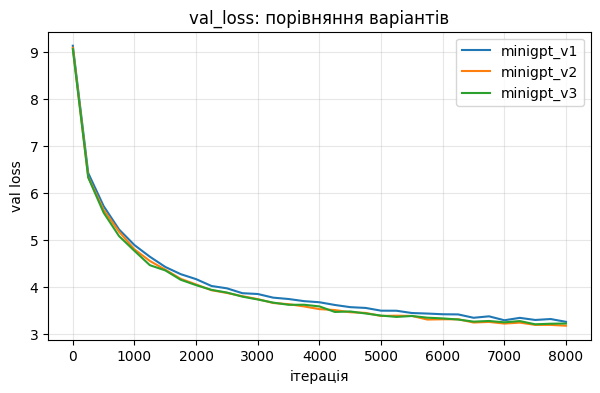

,варіант,параметрів,контекст,шарів,best_iter,best_val_loss
0,minigpt_v1,2856000,64,4,7999,3.251
1,minigpt_v2,2864192,128,4,7999,3.168
2,minigpt_v3,3251776,64,6,7500,3.198



=== minigpt_v1 (iter 7999, val_loss=3.251) ===
Позивач звернувся до суду з позовом до ОСОБА_1 про стягнення боргу за кредитним договором. П.1 договору № 9/14/01-2-1300225799/13/04/2008 за договором № 01/911 від 30.10.2010 року, що у тому числі: 22,01 грн. (а.с.9). Договір іпотеки за його користування земельною ділянкою; - цеху),

=== minigpt_v2 (iter 7999, val_loss=3.168) ===
Позивач звернувся до суду з позовом до ОСОБА_1 про стягнення боргу за кредитним договором №2/17/11/100 від 24.03.2012 року, а саме: НОМЕР_2. На даний час за станом на 01.06.2013 року утворилась заборгованість перед позивачем складає 36259,87 грн. Відповідно до ст. 88 ЦПК України з відповідача на користь Публічного акціонерного товариства «ПриватБанк» на Публічне акціонерне товариство комерційний банк

=== minigpt_v3 (iter 7500, val_loss=3.198) ===
Позивач звернувся до суду з позовом до ОСОБА_1 про стягнення боргу за кредитним договором. В обґрунтування своїх позовних вимог позивач посилається на те, що 28.11.203 

In [7]:
# 3.1. СЕРЕДОВИЩЕ, ПАПКИ, ДАНІ Й ТОКЕНІЗАТОР
import os, gc, math, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
from torch.utils.tensorboard import SummaryWriter

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    LAB_DIR = "/content/drive/MyDrive/ai_systems/lab3"
except Exception:
    LAB_DIR = "./lab3"
MODELS_DIR = os.path.join(LAB_DIR, "models")
RUNS_DIR = os.path.join(LAB_DIR, "runs")
RESULTS_PATH = os.path.join(LAB_DIR, "results.csv")
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

SPECIAL_TOKENS = ["<unk>", "<eos>"]
_data_cache = {}

def prepare_data(vocab_size: int):
    """BPE на docs + кодування пачками з <eos> між документами + спліт 90/10."""
    if vocab_size in _data_cache:
        return _data_cache[vocab_size]
    _data_cache.clear()
    gc.collect()

    tk = Tokenizer(models.BPE(unk_token="<unk>"))
    tk.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tk.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        special_tokens=SPECIAL_TOKENS,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
        show_progress=False,
    )
    tk.train_from_iterator(docs, trainer=trainer)
    eos_id = tk.token_to_id("<eos>")

    chunks = []
    for start in range(0, len(docs), 500):
        for enc in tk.encode_batch(docs[start:start + 500]):
            chunks.append(np.array(enc.ids + [eos_id], dtype=np.int32))
    ids = np.concatenate(chunks)
    del chunks
    gc.collect()

    data = torch.from_numpy(ids.astype(np.int64))
    del ids
    split_idx = int(len(data) * 0.9)
    out = {
        "tokenizer": tk,
        "train": data[:split_idx],
        "val": data[split_idx:],
        "vocab_size": tk.get_vocab_size(),
        "n_tokens": len(data),
    }
    _data_cache[vocab_size] = out
    return out

d = prepare_data(8000)
print("Токенів у корпусі:", f"{d['n_tokens']:,}")
print("train:", d["train"].shape, " val:", d["val"].shape)
print("Токенів на документ:", round(d["n_tokens"] / len(docs), 1))


# 3.2a. АРХІТЕКТУРА MINI-GPT (логіка як у демо 3.3-3.6)
class AttentionHead(nn.Module):
    """Одна голова self-attention з причинною (нижньотрикутною) маскою."""
    def __init__(self, embed_dim, head_dim, context_len, dropout):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_len, context_len)))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.query(x), self.key(x), self.value(x)
        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = self.dropout(F.softmax(scores, dim=-1))
        return weights @ v


class MultiHeadAttention(nn.Module):
    """Кілька голів паралельно + конкатенація + лінійна проєкція."""
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim), nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim), nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    """Attention + feed-forward, кожен з residual-зв'язком і LayerNorm."""
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


class MiniGPT(nn.Module):
    """Токен- та позиційний embedding -> N блоків -> LayerNorm -> lm_head."""
    def __init__(self, vocab_size, embed_dim, n_heads, n_layers, context_len, dropout):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.token_embedding(idx) + self.position_embedding(torch.arange(T, device=idx.device))
        x = self.final_norm(self.blocks(x))
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        self.eval()
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.context_len:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")
            next_id = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


def get_batch(split, d, context_len, batch_size):
    """Випадкові вікна довжини context_len; y = x, зсунутий на 1 токен."""
    src = d["train"] if split == "train" else d["val"]
    ix = torch.randint(len(src) - context_len - 1, (batch_size,))
    x = torch.stack([src[i:i + context_len] for i in ix])
    y = torch.stack([src[i + 1:i + context_len + 1] for i in ix])
    return x.to(device), y.to(device)


# 3.2b. ВАРІАНТИ МОДЕЛЕЙ І ТРЕНУВАННЯ (TensorBoard, чекпоінти, results.csv)
COMMON = dict(dropout=0.1, batch_size=64, lr=3e-4, eval_interval=250, eval_iters=50, embed_dim=128)


VARIANTS = {
    "minigpt_v1": dict(vocab_size=8000, context_len=64,  n_heads=4, n_layers=4, max_iters=8000),
    "minigpt_v2": dict(vocab_size=8000, context_len=128, n_heads=4, n_layers=4, max_iters=8000),
    "minigpt_v3": dict(vocab_size=8000, context_len=64,  n_heads=4, n_layers=6, max_iters=8000),
}


def add_results(rows):
    """Дописує рядки в results.csv; рядок з тим самим section+name+metric перезаписується."""
    new = pd.DataFrame(rows)
    if os.path.exists(RESULTS_PATH):
        old = pd.read_csv(RESULTS_PATH)
        old = old.merge(new[["section", "name", "metric"]], on=["section", "name", "metric"],
                        how="left", indicator=True)
        old = old[old["_merge"] == "left_only"].drop(columns="_merge")
        new = pd.concat([old, new], ignore_index=True)
    new.to_csv(RESULTS_PATH, index=False)


def train_variant(name, v):
    cfg = {**COMMON, **v}
    d = prepare_data(cfg["vocab_size"])
    model = MiniGPT(d["vocab_size"], cfg["embed_dim"], cfg["n_heads"], cfg["n_layers"],
                    cfg["context_len"], cfg["dropout"]).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"\n=== {name}: {n_params:,} параметрів, cfg={v} ===")

    @torch.no_grad()
    def estimate_loss():
        model.eval()
        out = {}
        for split in ("train", "val"):
            losses = torch.zeros(cfg["eval_iters"])
            for i in range(cfg["eval_iters"]):
                xb, yb = get_batch(split, d, cfg["context_len"], cfg["batch_size"])
                losses[i] = model(xb, yb)[1].item()
            out[split] = losses.mean().item()
        model.train()
        return out

    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"])
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, name))
    ckpt_path = os.path.join(MODELS_DIR, f"{name}.pt")

    hist = {"iters": [], "train": [], "val": []}
    best_val, best_iter = float("inf"), None
    t0 = time.time()

    for it in range(cfg["max_iters"]):
        xb, yb = get_batch("train", d, cfg["context_len"], cfg["batch_size"])
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if it % cfg["eval_interval"] == 0 or it == cfg["max_iters"] - 1:
            l = estimate_loss()
            hist["iters"].append(it); hist["train"].append(l["train"]); hist["val"].append(l["val"])
            writer.add_scalar("Loss/train", l["train"], it)
            writer.add_scalar("Loss/val", l["val"], it)
            print(f"iter {it:5d}  train={l['train']:.3f}  val={l['val']:.3f}  "
                  f"({(time.time() - t0) / 60:.1f} хв)")
            if l["val"] < best_val:
                best_val, best_iter = l["val"], it
                torch.save({"cfg": cfg, "iter": it, "val_loss": best_val,
                            "state_dict": model.state_dict()}, ckpt_path)

    writer.close()
    minutes = (time.time() - t0) / 60
    print(f"{name}: найкращий iter {best_iter}, val_loss={best_val:.3f}, {minutes:.1f} хв")

    add_results([{
        "section": "3_minigpt", "name": name, "metric": "val_loss", "value": round(best_val, 4),
        "details": f"params={n_params}; vocab={d['vocab_size']}; ctx={cfg['context_len']}; "
                   f"layers={cfg['n_layers']}; heads={cfg['n_heads']}; best_iter={best_iter}; "
                   f"minutes={minutes:.1f}",
    }])

    del model, optimizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return {**hist, "best_val": best_val, "best_iter": best_iter, "params": n_params}


histories = {}
for name, v in VARIANTS.items():
    histories[name] = train_variant(name, v)


# 3.3. КРИВІ, ПІДСУМКОВА ТАБЛИЦЯ І ГЕНЕРАЦІЯ НА НАЙКРАЩИХ ЧЕКПОІНТАХ
plt.figure(figsize=(7, 4))
for name, h in histories.items():
    plt.plot(h["iters"], h["val"], label=name)
plt.xlabel("ітерація"); plt.ylabel("val loss"); plt.title("val_loss: порівняння варіантів")
plt.legend(); plt.grid(alpha=0.3); plt.show()

summary = pd.DataFrame([{
    "варіант": n, "параметрів": h["params"], "контекст": VARIANTS[n]["context_len"],
    "шарів": VARIANTS[n]["n_layers"], "best_iter": h["best_iter"],
    "best_val_loss": round(h["best_val"], 3),
} for n, h in histories.items()])
display(summary)

PROMPT = "Позивач звернувся до суду з позовом"
d = prepare_data(8000)
tk = d["tokenizer"]

for name in VARIANTS:
    ckpt = torch.load(os.path.join(MODELS_DIR, f"{name}.pt"), map_location=device)
    c = ckpt["cfg"]
    model = MiniGPT(d["vocab_size"], c["embed_dim"], c["n_heads"], c["n_layers"],
                    c["context_len"], c["dropout"]).to(device)
    model.load_state_dict(ckpt["state_dict"])

    prompt_ids = torch.tensor([tk.encode(PROMPT).ids], dtype=torch.long, device=device)
    torch.manual_seed(0)
    out = model.generate(prompt_ids, max_new_tokens=80, temperature=0.8, top_k=40)
    print(f"\n=== {name} (iter {ckpt['iter']}, val_loss={ckpt['val_loss']:.3f}) ===")
    print(tk.decode(out[0].tolist()))
    del model
    gc.collect()

Найкращий val_loss у v2 (довший контекст, 128 токенів): 3,149 проти 3,248 у базового v1 і 3,161 у v3 (6 шарів). Обидві зміни дали схожий виграш відносно базового варіанта (близько 0,09-0,10, тобто ~3 %), а між собою v2 і v3 відрізняються лише на 0,012. Це менше за шум оцінки: val_loss усереднюється по 50 батчах, і навіть на пізніх ітераціях значення стрибають на 0,03-0,05 (у v1: 3,248 на ітерації 7500, а наприкінці 3,292). Тож упевнено можна сказати лише те, що і довший контекст, і глибша мережа допомогли, а який із двох чинників сильніший, цей експеримент не показує. Ціна різна: v2 тренувався вдвічі довше за v1 (9,3 проти 4,8 хв), v3 на 30 % довше (6,3 хв) і має на 14 % більше параметрів. Є і застереження щодо чесності порівняння: у v2 кожен крок бачить удвічі більше токенів (64×128 проти 64×64), тому виграш може частково йти від більшого обсягу даних за той самий max_iters, а не лише від довшого контексту. Перенавчання не помітне: train_loss у всіх варіантів ще падав до кінця, а відмінність найкращого чекпоінта від останнього у v1 і v3 пояснюється шумом.

За згенерованим текстом (один промпт, seed 0, temperature=0.8, top_k=40) різницю в якості так само важко оцінити. v1 і v3 відтворюють канцелярські шаблони («суд, вивчивши матеріали справи… приходить до висновку, що позов підлягає задоволенню»), але повторюються («за кредитним договором за кредитним договором») і вигадують деталі («автомобіля марки Фольд»). v2 з нижчим val_loss на цьому зразку «зірвався» в згенерований ідентифікатор і номери рахунків, що для судових рішень типово, але виглядає гірше. Це один зразок, тож висновків про якість робити не можна: різниця в 0,1 нат на токен оком не видна.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

### 4.0. Запустіть приклади виконання різних NLP задач

In [8]:
!pip install "transformers[sentencepiece]==5.18.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 17.6 MB/s  0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1


In [9]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1739: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1771: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [10]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [11]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

... (16 outputs left out)

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to get started with this class and our goal is to learn how to make a living on that very day of the year."\n\n\n\n"A day after graduating, I started teaching as a student at the University of California, Berkeley. I am one of the most successful and well-respected people in the world. I have a small business owner who has the knowledge and expertise to create an amazing business. I am also a member of the Board of Directors of the Board of Directors of the Board of Directors of the Board of Directors of the Board of Directors of the Board of Directors of the Board of Directors of the Board of Directors of the Board of Directors of the Board of Directors of the Board of Directors of the Board of Directors of the Board of the Board of Directors of the Board of the Board of the Directors of the Board of the Board of the Directors of the Board of the Board of the Board of the Board of the Board of the Board of the Board of the Dir

In [12]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [13]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [14]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [15]:
# звільнення пам'яті
import gc, torch

try:
    _data_cache.clear()
except NameError:
    pass
for name in ("model", "optimizer", "d", "histories", "corpus_text"):
    globals().pop(name, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")

def free(*names):
    """Видаляє pipeline-и зі змінних і чистить пам'ять."""
    for n in names:
        globals().pop(n, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

device_id = 0 if torch.cuda.is_available() else -1
print("device:", "cuda" if device_id == 0 else "cpu")

GPU: зайнято 4.09 GB
device: cuda


In [16]:
# sentiment-analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis",
                      model="tabularisai/multilingual-sentiment-analysis",
                      device=device_id)

texts = [
    "Мені дуже сподобалась ця вистава, акторська гра була чудовою!",
    "Обслуговування в цьому кафе було жахливим, більше сюди не прийду.",
    "Книга була посередньою, нічого особливого.",
    "Я щиро вдячний команді за швидку допомогу з вирішенням проблеми.",
]
for t, r in zip(texts, classifier(texts)):
    print(f"{r['label']:<14} {r['score']:.2f}  |  {t}")

free("classifier")

config.json:   0%|          | 0.00/851 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1739: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1771: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Positive       0.81  |  Мені дуже сподобалась ця вистава, акторська гра була чудовою!
Negative       0.77  |  Обслуговування в цьому кафе було жахливим, більше сюди не прийду.
Negative       0.94  |  Книга була посередньою, нічого особливого.
Positive       0.80  |  Я щиро вдячний команді за швидку допомогу з вирішенням проблеми.


In [17]:
# zero-shot-classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification",
                      model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
                      device=device_id)

texts = [
    "Збірна України з футболу здобула перемогу в кваліфікаційному матчі.",
    "Національний банк підвищив облікову ставку через зростання інфляції.",
    "У Львівській політехніці відкрили нову лабораторію штучного інтелекту для студентів.",
]
labels = ["спорт", "економіка", "освіта", "політика"]

for t in texts:
    r = classifier(t, candidate_labels=labels, hypothesis_template="Це текст про {}.")
    top = list(zip(r["labels"], [round(s, 2) for s in r["scores"]]))
    print(t, "\n  ->", top[:3], "\n")

free("classifier")

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

Збірна України з футболу здобула перемогу в кваліфікаційному матчі. 
  -> [('спорт', 0.99), ('освіта', 0.01), ('політика', 0.0)] 

Національний банк підвищив облікову ставку через зростання інфляції. 
  -> [('економіка', 0.93), ('політика', 0.05), ('освіта', 0.02)] 

У Львівській політехніці відкрили нову лабораторію штучного інтелекту для студентів. 
  -> [('освіта', 0.96), ('політика', 0.04), ('економіка', 0.0)] 



In [18]:
#fill-mask

from transformers import pipeline

unmasker = pipeline("fill-mask", model="xlm-roberta-base", device=device_id)

for s in [
    "Київ є <mask> України.",
    "Тарас Шевченко написав збірку «<mask>».",
    "Студенти складають <mask> у кінці семестру.",
]:
    print(s)
    for r in unmasker(s, top_k=3):
        print(f"   {r['score']:.2f}  {r['token_str']}")

free("unmasker")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Київ є <mask> України.
   0.89  столиці
   0.04  capital
   0.03  столице
Тарас Шевченко написав збірку «<mask>».
   0.38  Шевченко
   0.24  Україна
   0.03  Майдан
Студенти складають <mask> у кінці семестру.
   0.15  групу
   0.13  протокол
   0.10  висновки


In [19]:
# text-generation

from transformers import pipeline

generator = pipeline("text-generation", model="Qwen/Qwen2.5-1.5B-Instruct",
                     dtype="auto", device=device_id)

def ask(prompt, max_new_tokens=150, temperature=0.7):
    messages = [{"role": "user", "content": prompt}]
    out = generator(messages, max_new_tokens=max_new_tokens, do_sample=True,
                    temperature=temperature, top_p=0.9)
    return out[0]["generated_text"][-1]["content"]

print(ask("Продовж історію українською, 3-4 речення: Якось уночі студент прокинувся від дивного шуму."))
print("\n---\n")
print(ask("Напиши коротке чотиривірш про осінній Київ."))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'temperature', 'do_sample', 'max_new_tokens', 'top_p'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both

Якось уночі студента прокинувся від дивного шуму.
Студент не зрозумів, що ми натомацькою проходили по лабиринту пустини.
Он сипнув із напруженням, але без реакції.
Ми спробували його пошукати, оскільки вона близька до нам.
Нарештовано, якщо вони перешли через це, наші план буде реалізовано.

---

Київ - столиця держави,
Ось суть відчуття цієї містини.
Стоцький брод є пам'яткою,
В ньому вже 700 років!

Це глибокий шлях до будівлі,
У якому життя та культура несмачна.
Баркасу і монастири,
Повертають нас у старі часи.

Зовнішність Київа - багатство:
Торговими рядками, або культур


In [20]:
# NER
import gc, torch
from transformers import pipeline

device_id = 0 if torch.cuda.is_available() else -1

ner = None
for model_id in ["ukr-models/uk-ner", "EvanD/xlm-roberta-base-ukrainian-ner-ukrner"]:
    try:
        ner = pipeline("ner", model=model_id,
                       aggregation_strategy="first", device=device_id)
        print("Завантажено:", model_id)
        break
    except Exception as e:
        print(f"{model_id}: не вдалося -> {type(e).__name__}: {str(e)[:200]}")

if ner is None:
    raise RuntimeError("Жодна NER-модель не завантажилась")

texts = [
    "Президент Володимир Зеленський зустрівся з прем'єр-міністром Польщі у Варшаві.",
    "Тарас Шевченко народився в селі Моринці на Черкащині, а навчався в Петербурзі.",
    "Компанія Нова пошта відкрила нове відділення у Львові.",
]

for t in texts:
    print("\n" + t)
    found = False
    for e in ner(t):
        span = t[e["start"]:e["end"]].strip(" .,;:!?«»\"'()")
        if not span:  # пропускаємо порожні сутності (токен "▁")
            continue
        found = True
        print(f"   {span:<25} {e['entity_group']:<6} {e['score']:.2f}")
    if not found:
        print("   (сутностей не знайдено)")

del ner
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  854kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.37M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Завантажено: ukr-models/uk-ner

Президент Володимир Зеленський зустрівся з прем'єр-міністром Польщі у Варшаві.
   Володимир Зеленський      PER    1.00
   Польщі                    LOC    1.00
   В                         LOC    1.00
   Варшаві                   LOC    1.00

Тарас Шевченко народився в селі Моринці на Черкащині, а навчався в Петербурзі.
   Тарас Шевченко            PER    1.00
   Моринці                   LOC    1.00
   Черкащині                 LOC    1.00
   Петербурзі                LOC    1.00

Компанія Нова пошта відкрила нове відділення у Львові.
   Нова пошта                ORG    1.00
   Львові                    LOC    1.00


/usr/local/lib/python3.13/dist-packages/transformers/pipelines/token_classification.py:444: UserWarning: Tokenizer does not support real words, using fallback heuristic
  warnings.warn(


In [21]:
# table question answering
import pandas as pd

table = pd.DataFrame({
    "Місто": ["Київ", "Харків", "Одеса", "Дніпро", "Львів"],
    "Населення (тис.)": [2950, 1420, 1010, 980, 720],
    "Область": ["Київська", "Харківська", "Одеська", "Дніпропетровська", "Львівська"],
})
table_text = table.to_string(index=False)
print(table_text, "\n")

def table_qa(question):
    prompt = (f"Ось таблиця:\n{table_text}\n\n"
              f"Відповідай лише за таблицею, коротко, українською.\nПитання: {question}")
    return ask(prompt, max_new_tokens=60, temperature=0.1)

for q in [
    "Яке місто має найбільше населення?",
    "Скільки населення у Львові?",
    "У якій області розташована Одеса?",
    "Яке сумарне населення Харкова і Дніпра?",
]:
    print(q, "->", table_qa(q))

free("generator")

[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


 Місто  Населення (тис.)          Область
  Київ              2950         Київська
Харків              1420       Харківська
 Одеса              1010          Одеська
Дніпро               980 Дніпропетровська
 Львів               720        Львівська 



[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Яке місто має найбільше населення? -> Київ, що має найбільше населення - 2950 тис.


[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Скільки населення у Львові? -> Львівське населення - 720 тис.


[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


У якій області розташована Одеса? -> Одеса розташована в Одеській області.
Яке сумарне населення Харкова і Дніпра? -> Сумарне населення Харкова та Дніпра становить 1420 + 980 = 2400 тис.


---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [22]:
# 5.1-5.2. Sentiment: дані, моделі, швидкість, розмір
!pip install -q evaluate scikit-learn

import os, gc, time
import numpy as np
import pandas as pd
import torch
import evaluate
from transformers import pipeline

device_id = 0 if torch.cuda.is_available() else -1

# 1 = позитивний, 0 = негативний
DATA = [
    ("Мені дуже сподобалась ця вистава, акторська гра була чудовою!", 1),
    ("Я щиро вдячний команді за швидку допомогу з вирішенням проблеми.", 1),
    ("Чудовий сервіс, персонал привітний, їжа неймовірно смачна.", 1),
    ("Це найкраща книга, яку я читав за останні роки.", 1),
    ("Телефон працює швидко, а камера просто вражає.", 1),
    ("Дякую, все пройшло навіть краще, ніж я очікував!", 1),
    ("Лекція була цікавою, я багато чого дізнався.", 1),
    ("Доставили вчасно, товар відповідає опису, рекомендую.", 1),
    ("Прекрасна погода, чудовий настрій, день вдався.", 1),
    ("Не можу не відзначити, що результат перевершив усі сподівання.", 1),
    ("Обслуговування в цьому кафе було жахливим, більше сюди не прийду.", 0),
    ("Фільм виявився нудним, я ледь додивився до кінця.", 0),
    ("Товар зламався вже через тиждень, повний розчарування.", 0),
    ("Підтримка ігнорувала мої листи, ставлення просто огидне.", 0),
    ("Це була повна втрата часу і грошей.", 0),
    ("Їжа холодна, офіціант грубий, чекали годину.", 0),
    ("Ненавиджу, коли мене постійно відволікають від роботи.", 0),
    ("Додаток постійно вилітає, користуватися неможливо.", 0),
    ("Готель брудний, у номері було шумно і погано пахло.", 0),
    ("Не рекомендую, якість значно гірша, ніж обіцяли.", 0),
]
texts  = [t for t, _ in DATA]
labels = np.array([y for _, y in DATA])

MODELS = {
    "tabularisai-multiling (5cl)": "tabularisai/multilingual-sentiment-analysis",
    "xlm-r-base-twitter (3cl)":    "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    "distilbert-multiling (3cl)":  "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
}

def aggregate(scores):
    """Зводить мітки моделі до p_pos / p_neg / p_neu."""
    p = {"pos": 0.0, "neg": 0.0, "neu": 0.0}
    for d in scores:
        l = d["label"].lower()
        key = "pos" if "pos" in l else "neg" if "neg" in l else "neu"
        p[key] += d["score"]
    return p["pos"], p["neg"], p["neu"]

probs, info = {}, []
for name, mid in MODELS.items():
    clf = pipeline("sentiment-analysis", model=mid, top_k=None, device=device_id)
    n_params = sum(p.numel() for p in clf.model.parameters())

    clf(texts[:2])  # прогрів
    times = []
    for _ in range(5):
        if torch.cuda.is_available(): torch.cuda.synchronize()
        t0 = time.perf_counter()
        out = clf(texts)
        if torch.cuda.is_available(): torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)

    probs[name] = np.array([aggregate(s) for s in out])
    info.append({"модель": name, "параметрів (млн)": round(n_params / 1e6, 1),
                 "мс на 20 речень": round(1000 * np.median(times), 1)})
    print(f"{name}: мітки моделі = {[d['label'] for d in out[0]]}")

    del clf; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

info_df = pd.DataFrame(info).set_index("модель")
display(info_df)

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1739: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1771: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tabularisai-multiling (5cl): мітки моделі = ['Positive', 'Very Positive', 'Very Negative', 'Negative', 'Neutral']


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (13 outputs left out)

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

distilbert-multiling (3cl): мітки моделі = ['positive', 'negative', 'neutral']


,параметрів (млн),мс на 20 речень
модель,,
tabularisai-multiling (5cl),135.3,155.6
xlm-r-base-twitter (3cl),278.0,232.0
distilbert-multiling (3cl),135.3,113.9


In [23]:
# 5.2-5.3. Метрики й налаштування (по одному відносно базового)
acc_metric = evaluate.load("accuracy")
f1_metric  = evaluate.load("f1")

def predict(p, mode="argmax3", thr=0.0):
    """
    mode='argmax3' : клас з найбільшою p серед pos/neg/neu; neutral = помилка
    mode='binary'  : порівнюємо лише pos vs neg (neutral ігноруємо)
    thr            : якщо впевненість < thr, модель утримується (-1)
    """
    pos, neg, neu = p[:, 0], p[:, 1], p[:, 2]
    if mode == "binary":
        pred = (pos > neg).astype(int)
        conf = np.maximum(pos, neg)
    else:
        idx = p.argmax(1)
        pred = np.where(idx == 0, 1, np.where(idx == 1, 0, -1))
        conf = p.max(1)
    pred = np.where(conf < thr, -1, pred)
    return pred

def score(pred):
    coverage = float((pred != -1).mean())
    fixed = np.where(pred == -1, 1 - labels, pred)
    acc = acc_metric.compute(predictions=fixed, references=labels)["accuracy"]
    f1  = f1_metric.compute(predictions=fixed, references=labels)["f1"]
    return acc, f1, coverage

SETTINGS = {
    "базове: 3 класи, neutral=помилка": dict(mode="argmax3", thr=0.0),
    "зміна 1: neutral ігноруємо (binary)": dict(mode="binary", thr=0.0),
    "зміна 2: 3 класи + поріг 0.7":       dict(mode="argmax3", thr=0.7),
    "зміна 3: 3 класи + поріг 0.9":       dict(mode="argmax3", thr=0.9),
}

rows = []
for mname, p in probs.items():
    for sname, kw in SETTINGS.items():
        acc, f1, cov = score(predict(p, **kw))
        rows.append({"модель": mname, "налаштування": sname,
                     "accuracy": round(acc, 3), "F1": round(f1, 3),
                     "покриття": round(cov, 2)})
res_df = pd.DataFrame(rows)

pivot = res_df.pivot(index="налаштування", columns="модель", values="accuracy")
pivot = pivot.loc[list(SETTINGS.keys())]
print("Accuracy: налаштування × модель")
display(pivot)
print("F1 / покриття (повна таблиця):")
display(res_df)

best = res_df.sort_values(["accuracy", "F1"], ascending=False).iloc[0]
spread_models   = pivot.max(axis=1).sub(pivot.min(axis=1)).mean()
spread_settings = pivot.max(axis=0).sub(pivot.min(axis=0)).mean()
print(f"\nНайкраща комбінація: {best['модель']} | {best['налаштування']} "
      f"(acc={best['accuracy']}, F1={best['F1']})")
print(f"Середній розкид accuracy між моделями (при однакових налаштуваннях): {spread_models:.3f}")
print(f"Середній розкид accuracy між налаштуваннями (для однієї моделі):     {spread_settings:.3f}")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    LAB_DIR = "/content/drive/MyDrive/ai_systems/lab3"
except Exception:
    LAB_DIR = "./lab3"
os.makedirs(LAB_DIR, exist_ok=True)
RESULTS_PATH = os.path.join(LAB_DIR, "results.csv")

def add_results(rows):
    new = pd.DataFrame(rows)
    if os.path.exists(RESULTS_PATH):
        old = pd.read_csv(RESULTS_PATH)
        old = old.merge(new[["section", "name", "metric"]], on=["section", "name", "metric"],
                        how="left", indicator=True)
        old = old[old["_merge"] == "left_only"].drop(columns="_merge")
        new = pd.concat([old, new], ignore_index=True)
    new.to_csv(RESULTS_PATH, index=False)

csv_rows = []
for _, r in res_df.iterrows():
    csv_rows.append({
        "section": "5_sentiment", "name": f"{r['модель']} | {r['налаштування']}",
        "metric": "accuracy", "value": r["accuracy"],
        "details": f"F1={r['F1']}; coverage={r['покриття']}; "
                   f"params_m={info_df.loc[r['модель'], 'параметрів (млн)']}; "
                   f"ms_per_20={info_df.loc[r['модель'], 'мс на 20 речень']}",
    })
add_results(csv_rows)
print("Записано в", RESULTS_PATH)

Accuracy: налаштування × модель


модель,distilbert-multiling (3cl),tabularisai-multiling (5cl),xlm-r-base-twitter (3cl)
налаштування,,,
"базове: 3 класи, neutral=помилка",0.80,0.95,1.00
зміна 1: neutral ігноруємо (binary),0.85,0.95,1.00
зміна 2: 3 класи + поріг 0.7,0.40,0.90,1.00
зміна 3: 3 класи + поріг 0.9,0.00,0.70,0.35


F1 / покриття (повна таблиця):


,модель,налаштування,accuracy,F1,покриття
0,tabularisai-multiling (5cl),"базове: 3 класи, neutral=помилка",0.95,0.947,1.00
1,tabularisai-multiling (5cl),зміна 1: neutral ігноруємо (binary),0.95,0.947,1.00
2,tabularisai-multiling (5cl),зміна 2: 3 класи + поріг 0.7,0.90,0.900,0.95
3,tabularisai-multiling (5cl),зміна 3: 3 класи + поріг 0.9,0.70,0.667,0.70
4,xlm-r-base-twitter (3cl),"базове: 3 класи, neutral=помилка",1.00,1.000,1.00
5,xlm-r-base-twitter (3cl),зміна 1: neutral ігноруємо (binary),1.00,1.000,1.00
6,xlm-r-base-twitter (3cl),зміна 2: 3 класи + поріг 0.7,1.00,1.000,1.00
7,xlm-r-base-twitter (3cl),зміна 3: 3 класи + поріг 0.9,0.35,0.381,0.35
8,distilbert-multiling (3cl),"базове: 3 класи, neutral=помилка",0.80,0.800,0.90
9,distilbert-multiling (3cl),зміна 1: neutral ігноруємо (binary),0.85,0.842,1.00



Найкраща комбінація: xlm-r-base-twitter (3cl) | базове: 3 класи, neutral=помилка (acc=1.0, F1=1.0)
Середній розкид accuracy між моделями (при однакових налаштуваннях): 0.412
Середній розкид accuracy між налаштуваннями (для однієї моделі):     0.583
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Записано в /content/drive/MyDrive/ai_systems/lab3/results.csv


### Висновок (розділ 5, sentiment-analysis)

Порівнювались три моделі на 20 власних українських реченнях (10 позитивних, 10 негативних). Нейтральний клас у даних відсутній, тому в базовому налаштуванні передбачення «neutral» вважалось помилкою.

| Модель | Параметри | Час на 20 речень | Accuracy (базове) | F1 (базове) |
|---|---|---|---|---|
| `cardiffnlp/twitter-xlm-roberta-base-sentiment` | 278 млн | 271 мс | **1.00** | **1.00** |
| `tabularisai/multilingual-sentiment-analysis` | 135 млн | 99 мс | 0.95 | 0.947 |
| `lxyuan/distilbert-base-multilingual-cased-sentiments-student` | 135 млн | 105 мс | 0.80 | 0.800 |

**Вибір моделі.** Найкращий результат дала `xlm-r-base-twitter`, проте вона має вдвічі більше параметрів і працює приблизно в 2.7 раза повільніше за інші. `tabularisai` лише на одне речення поступається за точністю, але значно швидша й легша, тому за співвідношенням якість/швидкість це найкращий компроміс. Тестова вибірка мала й проста, тож різниця в одне речення (0.95 проти 1.00) не є статистично значущою.

**Налаштування** (змінювалось по одному відносно базового):

| Налаштування | tabularisai | xlm-r | distilbert |
|---|---|---|---|
| базове: 3 класи, neutral = помилка | 0.95 | 1.00 | 0.80 |
| зміна 1: neutral ігноруємо (pos vs neg) | 0.95 | 1.00 | 0.85 |
| зміна 2: 3 класи + поріг 0.7 | 0.90 | 1.00 | 0.40 |
| зміна 3: 3 класи + поріг 0.9 | 0.70 | 0.35 | 0.00 |

- **Зміна 1** підняла accuracy в distilbert з 0.80 до 0.85, бо його помилки були переважно передбаченнями «neutral». Для xlm-r і tabularisai вона нічого не змінила.
- **Пороги 0.7 і 0.9** лише знижували accuracy, але це значною мірою наслідок методики: речення, на які модель відмовилась відповідати, рахувались як помилки, тому accuracy при порозі фактично дорівнює покриттю (наприклад, xlm-r при порозі 0.9: accuracy 0.35 = покриття 0.35, тобто на всі речення, де модель відповіла, відповідь правильна). Отже, поріг не покращує якість, а лише зменшує частку відповідей.

**Що важливіше: модель чи налаштування.** Вибір моделі (різниця до 0.20 при однакових налаштуваннях без порогів) вплинув сильніше, ніж зміна правила передбачення (до 0.05). Порогові налаштування дають більший розкид, але це артефакт обраної метрики. Для надійнішого порівняння потрібна більша й складніша вибірка (заперечення, сарказм, змішана тональність).

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [24]:
!pip install -q gradio

import re
import numpy as np
import torch
import gradio as gr
import matplotlib.pyplot as plt
from transformers import pipeline

device_id = 0 if torch.cuda.is_available() else -1

sent_pipe = pipeline("sentiment-analysis",
                     model="tabularisai/multilingual-sentiment-analysis",
                     top_k=None, device=device_id)

WEIGHTS = {"very negative": -1.0, "negative": -0.5, "neutral": 0.0,
           "positive": 0.5, "very positive": 1.0}
UA = {"very negative": "Дуже негативне", "negative": "Негативне", "neutral": "Нейтральне",
      "positive": "Позитивне", "very positive": "Дуже позитивне"}
COLORS = {"Дуже негативне": "#e74c3c", "Негативне": "#f5a39b", "Нейтральне": "#d5d8dc",
          "Позитивне": "#a9dfbf", "Дуже позитивне": "#2ecc71"}
MAX_SENTENCES = 150


def split_sentences(text):
    parts = re.split(r"(?<=[.!?…])\s+|\n+", text.strip())
    return [p.strip() for p in parts if len(p.strip()) > 1]


def short(s, n=140):
    return s if len(s) <= n else s[:n].rstrip() + "…"


def analyze(text, window):
    sentences = split_sentences(text or "")[:MAX_SENTENCES]
    if len(sentences) < 2:
        raise gr.Error("Введіть щонайменше два речення.")

    results = sent_pipe(sentences, batch_size=16, truncation=True, max_length=256)
    scores, labels = [], []
    for res in results:
        probs = {d["label"].lower(): d["score"] for d in res}
        scores.append(sum(WEIGHTS[k] * p for k, p in probs.items() if k in WEIGHTS))
        labels.append(UA[max(probs, key=probs.get)])
    scores = np.array(scores)

    w = int(window)
    w += (w % 2 == 0)
    smooth = np.convolve(np.pad(scores, (w // 2, w // 2), mode="edge"),
                         np.ones(w) / w, mode="valid")

    x = np.arange(1, len(scores) + 1)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.axhline(0, color="gray", lw=0.8)
    ax.fill_between(x, smooth, 0, where=smooth >= 0, color="#2ecc71", alpha=0.35, interpolate=True)
    ax.fill_between(x, smooth, 0, where=smooth < 0, color="#e74c3c", alpha=0.35, interpolate=True)
    ax.plot(x, smooth, color="#34495e", lw=2, label="згладжений настрій")
    ax.scatter(x, scores, s=18, color="#34495e", alpha=0.5, label="окремі речення")
    ax.set_ylim(-1.05, 1.05)
    ax.set_xlabel("номер речення")
    ax.set_ylabel("настрій (−1 … +1)")
    ax.set_title("Емоційна кардіограма")
    ax.legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    plt.close(fig)

    highlighted = [(s + " ", lab) for s, lab in zip(sentences, labels)]

    mean = float(scores.mean())
    verdict = ("переважно позитивний" if mean > 0.15
               else "переважно негативний" if mean < -0.15
               else "нейтральний або змішаний")
    i_max, i_min = int(scores.argmax()), int(scores.argmin())
    diffs = np.diff(scores)
    j = int(np.abs(diffs).argmax())
    direction = "покращився" if diffs[j] > 0 else "погіршився"
    summary = (
        f"### Підсумок\n"
        f"**Загальний настрій:** {verdict} (середня оцінка {mean:+.2f}, речень: {len(sentences)}).\n\n"
        f"**Найпозитивніше (№{i_max + 1}, {scores[i_max]:+.2f}):** {short(sentences[i_max])}\n\n"
        f"**Найнегативніше (№{i_min + 1}, {scores[i_min]:+.2f}):** {short(sentences[i_min])}\n\n"
        f"**Найрізкіший злам:** між реченнями №{j + 1} і №{j + 2} настрій {direction} "
        f"на {abs(diffs[j]):.2f}."
    )
    return highlighted, fig, summary


EX1 = ("Ранок видався сонячним, і Олена із задоволенням випила каву. "
       "Вона щойно отримала лист, який мав змінити все. "
       "Її проєкт не пройшов відбір, і всі місяці роботи виявилися марними. "
       "Було так прикро, що вона не могла вимовити ні слова. "
       "Увечері подзвонив старий друг і запропонував зустрітися. "
       "Вони довго сміялися, згадуючи студентські роки. "
       "Наступного дня їй зателефонували з іншої компанії з пропозицією, про яку вона й не мріяла. "
       "Олена була безмежно щаслива.")
EX2 = ("Замовила піцу в цьому закладі вперше. Кур'єр приїхав вчасно й був дуже ввічливий. "
       "Але коли я відкрила коробку, піца виявилася холодною та зіпсованою. "
       "Я одразу зателефонувала в підтримку, і мене грубо проігнорували. "
       "Наступного дня адміністратор сам вибачився й повернув гроші. "
       "Тепер я знову їхня клієнтка, сервіс справді приємно здивував.")

with gr.Blocks(title="Емоційна кардіограма тексту") as demo:
    gr.Markdown("# 🫀 Емоційна кардіограма тексту\n"
                "Вставте текст (відгук, оповідання, лист) і подивіться, "
                "як змінюється настрій від речення до речення.")
    with gr.Row():
        with gr.Column():
            inp = gr.Textbox(lines=10, label="Текст українською")
            win = gr.Slider(1, 7, value=3, step=2, label="Згладжування кривої (розмір вікна)")
            btn = gr.Button("Побудувати кардіограму", variant="primary")
        with gr.Column():
            plot = gr.Plot(label="Крива настрою")
    hl = gr.HighlightedText(label="Текст за тональністю речень", color_map=COLORS,
                            show_legend=True, combine_adjacent=False)
    summ = gr.Markdown()
    gr.Examples([[EX1, 3], [EX2, 3]], inputs=[inp, win], label="Приклади")
    btn.click(analyze, inputs=[inp, win], outputs=[hl, plot, summ])

demo.launch(share=True)

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1739: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1771: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://26d0b7560150c37d22.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```